# 꼬리(극단 SFR) 오차 줄이기 — 0단계: 진단 (james, 최종 보고서용 작업)

- 목적: 현재 예비 모델(2단계 `TwoStageSFR`, 중간 보고서 7절)이 **꼬리 은하를 왜, 어디서 못 맞히는지** 숫자로 확인한다.
- 데이터: 템플릿과 같은 분할의 **학습 데이터 166,749개만** 사용. 평가는 조장 5절과 같은 **학습 데이터 안 5-fold CV**(KFold, shuffle, seed 42)의 out-of-fold(OOF) 예측으로 한다. **검증 데이터는 쓰지 않는다.**
- 모델 코드는 제출본 `DataHub_701104_mid.ipynb` 7절의 `TwoStageSFR`, `HGB` 설정을 그대로 옮겼다. 고치거나 튜닝하지 않는다(진단만).


In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 100)
CSV = "Galaxy Features with Position and Velocity for Star Formation Rate Prediction.csv"
DATA_PATH = next(p for p in [Path(CSV), Path("../../") / CSV] if p.exists())
df = pd.read_csv(DATA_PATH)
TARGET, ID_COLUMN = "sfr_linear", "subhalo_id"
FINAL_FEATURES = [c for c in df.columns if c not in [ID_COLUMN, TARGET]]

# 템플릿 5절(DO NOT MODIFY)과 같은 분할
X, y = df[FINAL_FEATURES], df[TARGET]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_SEED, stratify=(y > 0).astype(int))
del X_val, y_val   # 이 노트북에서는 검증 데이터를 쓰지 않는다
print("전체:", len(df), "| 학습:", len(X_train))


전체: 208437 | 학습: 166749


In [2]:
# 꼬리는 몇 개인가 — 전체 데이터와 학습 데이터 (기준별)
y_all, y_tr = df[TARGET], y_train
q_all = {"상위 10%": y_all.quantile(0.90), "상위 1%": y_all.quantile(0.99), "상위 0.1%": y_all.quantile(0.999)}
q_tr = {"상위 10%": y_tr.quantile(0.90), "상위 1%": y_tr.quantile(0.99), "상위 0.1%": y_tr.quantile(0.999)}
rows = []
for name, thr_all, thr_tr in [("SFR > 10", 10, 10), ("SFR > 30", 30, 30), ("SFR > 100", 100, 100), ("SFR > 500", 500, 500),
                              *[(f"{k}", q_all[k], q_tr[k]) for k in q_all]]:
    rows.append({"기준": name,
                 "전체 기준값": round(thr_all, 2), "전체 개수": int((y_all > thr_all).sum() if name.startswith("SFR") else (y_all >= thr_all).sum()),
                 "학습 기준값": round(thr_tr, 2), "학습 개수": int((y_tr > thr_tr).sum() if name.startswith("SFR") else (y_tr >= thr_tr).sum())})
tail_counts = pd.DataFrame(rows).set_index("기준")
tail_counts["전체 비율(%)"] = tail_counts["전체 개수"] / len(df) * 100
tail_counts["학습 비율(%)"] = tail_counts["학습 개수"] / len(y_tr) * 100
display(tail_counts.round(3))
print("SFR = 0: 전체", int((y_all == 0).sum()), "| 학습", int((y_tr == 0).sum()))


,전체 기준값,전체 개수,학습 기준값,학습 개수,전체 비율(%),학습 비율(%)
기준,,,,,,
SFR > 10,10.00,14634,10.00,11696,7.021,7.014
SFR > 30,30.00,2704,30.00,2169,1.297,1.301
SFR > 100,100.00,270,100.00,209,0.130,0.125
SFR > 500,500.00,13,500.00,10,0.006,0.006
상위 10%,7.55,20844,7.55,16675,10.000,10.000
상위 1%,34.86,2085,35.01,1668,1.000,1.000
상위 0.1%,112.78,209,110.60,167,0.100,0.100


SFR = 0: 전체 18048 | 학습 14438


In [3]:
# 제출본 7절의 모델을 그대로 (설정 변경 없음)
HGB = dict(learning_rate=0.08, max_iter=150, max_leaf_nodes=31, random_state=RANDOM_SEED)

class TwoStageSFR:
    """분류기 P(y>0|x)와 양수 은하만으로 학습한 회귀기 E[y|y>0,x]를 곱하는 모델 (제출본 7절과 같음)."""
    def __init__(self, hgb_params, reg_loss="squared_error", clip_zero=True):
        self.hgb_params, self.reg_loss, self.clip_zero = hgb_params, reg_loss, clip_zero
    def fit(self, X, y):
        y = np.asarray(y, dtype=float); pos = y > 0
        self.clf_ = HistGradientBoostingClassifier(**self.hgb_params).fit(X, pos.astype(int))
        self.reg_ = HistGradientBoostingRegressor(loss=self.reg_loss, **self.hgb_params).fit(X[pos], y[pos])
        return self
    def predict_proba_positive(self, X): return self.clf_.predict_proba(X)[:, 1]
    def predict_positive_mean(self, X):
        e = self.reg_.predict(X); return np.clip(e, 0, None) if self.clip_zero else e
    def predict(self, X): return self.predict_proba_positive(X) * self.predict_positive_mean(X)

def rmse(a, b): return mean_squared_error(a, b) ** 0.5

# 조장 5절과 같은 fold
Xtr = X_train.reset_index(drop=True); ytr = y_train.reset_index(drop=True)
FOLDS = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED).split(Xtr))
oof = {"HGB 기준선": np.zeros(len(ytr)), "2단계 (현재 모델)": np.zeros(len(ytr))}
oof_p, oof_e = np.zeros(len(ytr)), np.zeros(len(ytr))
fold_info = []
t0 = time.time()
for k, (tr, te) in enumerate(FOLDS):
    base = HistGradientBoostingRegressor(**HGB).fit(Xtr.iloc[tr], ytr.iloc[tr])
    two = TwoStageSFR(HGB).fit(Xtr.iloc[tr], ytr.iloc[tr])
    oof["HGB 기준선"][te] = base.predict(Xtr.iloc[te])
    oof_p[te] = two.predict_proba_positive(Xtr.iloc[te]); oof_e[te] = two.predict_positive_mean(Xtr.iloc[te])
    oof["2단계 (현재 모델)"][te] = oof_p[te] * oof_e[te]
    yt = ytr.iloc[te].to_numpy()
    fold_info.append({"fold": k + 1, "SFR>100 개수": int((yt > 100).sum()), "fold 최대 SFR": round(yt.max(), 1),
                      "기준선 RMSE": rmse(yt, oof["HGB 기준선"][te]), "2단계 RMSE": rmse(yt, oof["2단계 (현재 모델)"][te]),
                      "기준선 트리 수": base.n_iter_, "분류기 트리 수": two.clf_.n_iter_, "양수 회귀기 트리 수": two.reg_.n_iter_})
print(f"5-fold 학습·예측 {time.time() - t0:.0f}초")
display(pd.DataFrame(fold_info).set_index("fold").round(3))
yv = ytr.to_numpy()
for k, p in oof.items():
    print(f"{k}: OOF 전체 RMSE {rmse(yv, p):.3f} | fold 평균 {np.mean([rmse(yv[te], p[te]) for _, te in FOLDS]):.3f}")


5-fold 학습·예측 7초


,SFR>100 개수,fold 최대 SFR,기준선 RMSE,2단계 RMSE,기준선 트리 수,분류기 트리 수,양수 회귀기 트리 수
fold,,,,,,,
1,58,2145.4,14.443,14.239,84,150,59
2,49,1413.7,10.325,10.571,35,150,54
3,31,564.1,6.007,6.235,41,106,35
4,36,463.3,5.399,5.548,47,150,29
5,35,334.2,5.451,5.680,30,150,47


HGB 기준선: OOF 전체 RMSE 9.057 | fold 평균 8.325
2단계 (현재 모델): OOF 전체 RMSE 9.126 | fold 평균 8.455


In [4]:
# 진단 1. 오차가 어디서 나오나 — 실제 SFR 구간별 (2단계 모델의 OOF 예측)
pred = oof["2단계 (현재 모델)"]
res = pred - yv                              # 음수 = 과소예측
bins = [-0.1, 0, 1, 3, 10, 30, 100, 300, np.inf]
labels = ["0", "(0, 1]", "(1, 3]", "(3, 10]", "(10, 30]", "(30, 100]", "(100, 300]", "> 300"]
b = pd.cut(yv, bins=bins, labels=labels)
sse_total = (res ** 2).sum()
g = pd.DataFrame({"y": yv, "pred": pred, "res": res, "sq": res ** 2, "b": b}).groupby("b", observed=True)
err_tab = pd.DataFrame({
    "은하 수": g.size(),
    "은하 비율(%)": g.size() / len(yv) * 100,
    "실제 평균": g["y"].mean(),
    "예측 평균": g["pred"].mean(),
    "평균 잔차 (예측-실제)": g["res"].mean(),
    "구간 RMSE": np.sqrt(g["sq"].mean()),
    "오차제곱합 비중(%)": g["sq"].sum() / sse_total * 100,
})
display(err_tab.round(2))
for thr in (30, 100):
    m = yv > thr
    perfect = pred.copy(); perfect[m] = yv[m]
    print(f"SFR > {thr} 은하({m.sum():,}개, {m.mean():.2%})를 완벽히 맞히면: OOF RMSE {rmse(yv, pred):.3f} → {rmse(yv, perfect):.3f}")


,은하 수,은하 비율(%),실제 평균,예측 평균,평균 잔차 (예측-실제),구간 RMSE,오차제곱합 비중(%)
b,,,,,,,
0,14438,8.66,0.00,0.53,0.53,1.91,0.38
"(0, 1]",32767,19.65,0.70,1.30,0.59,1.30,0.40
"(1, 3]",73740,44.22,1.76,1.90,0.15,1.00,0.53
"(3, 10]",34108,20.45,5.19,5.20,0.00,5.17,6.56
"(10, 30]",9527,5.71,16.01,15.71,-0.30,9.53,6.23
"(30, 100]",1960,1.18,47.71,42.83,-4.88,18.91,5.05
"(100, 300]",181,0.11,145.66,76.82,-68.85,89.15,10.36
> 300,28,0.02,531.06,75.38,-455.67,591.36,70.51


SFR > 30 은하(2,169개, 1.30%)를 완벽히 맞히면: OOF RMSE 9.126 → 3.425
SFR > 100 은하(209개, 0.13%)를 완벽히 맞히면: OOF RMSE 9.126 → 3.992


In [5]:
# 진단 2. 예측이 얼마나 높이 올라가나 — 꼬리에서의 예측 상한과 과소예측 정도
tail100, tail30 = yv > 100, (yv > 30) & (yv <= 100)
print(f"OOF 예측 최댓값: {pred.max():.1f} (양수 회귀기 출력 최댓값 {oof_e.max():.1f}) | 실제 최댓값 {yv.max():.1f}")
print(f"예측이 100을 넘은 은하: {(pred > 100).sum()}개 (실제 SFR > 100: {tail100.sum()}개)")
ratio = pd.DataFrame({
    "SFR > 100": pd.Series(pred[tail100] / yv[tail100]).describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]),
    "30 < SFR ≤ 100": pd.Series(pred[tail30] / yv[tail30]).describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]),
})
print("예측 / 실제 비율 (1이면 정확, 0.5면 절반으로 예측):")
display(ratio.round(3))
print(f"SFR > 100 은하의 분류기 P(SFR>0) 평균 {oof_p[tail100].mean():.4f}, 최솟값 {oof_p[tail100].min():.4f} "
      f"→ 꼬리 오차는 거의 전부 양수 회귀기 몫")


OOF 예측 최댓값: 254.3 (양수 회귀기 출력 최댓값 254.5) | 실제 최댓값 2145.4
예측이 100을 넘은 은하: 144개 (실제 SFR > 100: 209개)
예측 / 실제 비율 (1이면 정확, 0.5면 절반으로 예측):


,SFR > 100,30 < SFR ≤ 100
count,209.000,1960.000
mean,0.514,0.917
std,0.285,0.386
min,0.000,0.078
10%,0.111,0.597
25%,0.298,0.717
50%,0.543,0.851
75%,0.708,1.042
90%,0.820,1.284
max,1.480,5.540


SFR > 100 은하의 분류기 P(SFR>0) 평균 0.9918, 최솟값 0.6056 → 꼬리 오차는 거의 전부 양수 회귀기 몫


In [6]:
# 진단 3. 어떤 꼬리 은하를 특히 못 맞히나 — 특성 비교 (학습 OOF)
feat = Xtr.copy()
feat["병합 후보"] = (feat["log10_mass_ratio"] > -6).astype(float)
feat["성장량 (M* - M*_prog)"] = np.where(feat["log10_main_prog_stellar_mass"] > 6.0,
                                        feat["log10_stellar_mass"] - feat["log10_main_prog_stellar_mass"], np.nan)
cols = ["log10_stellar_mass", "log10_halo_mass", "log10_BH_mass", "log10_overdensity_plus_1", "병합 후보", "성장량 (M* - M*_prog)"]
pos_all = yv > 0
in_tail = yv > 100
ratio_t = pred / np.where(yv > 0, yv, np.nan)
worst = in_tail & (ratio_t < np.nanmedian(ratio_t[in_tail]))     # 꼬리 중 예측/실제 비율이 중앙값보다 낮은 절반
better = in_tail & ~worst
comp = pd.DataFrame({
    "SFR > 0 전체": feat[pos_all][cols].median(),
    "10 < SFR ≤ 100": feat[(yv > 10) & (yv <= 100)][cols].median(),
    "SFR > 100 전체": feat[in_tail][cols].median(),
    "SFR > 100 중 덜 틀린 절반": feat[better][cols].median(),
    "SFR > 100 중 많이 틀린 절반": feat[worst][cols].median(),
})
comp.loc["병합 후보"] = [feat.loc[m, "병합 후보"].mean() * 100 for m in (pos_all, (yv > 10) & (yv <= 100), in_tail, better, worst)]
comp = comp.rename(index={"병합 후보": "병합 후보 비율(%)"})
comp.loc["은하 수"] = [int(m.sum()) for m in (pos_all, (yv > 10) & (yv <= 100), in_tail, better, worst)]
display(comp.round(3))

# 꼬리 안에서 '얼마나 과소예측했나'(log 예측/실제)와 각 피처의 순위 상관
lr_t = np.log10(np.clip(pred[in_tail], 1e-3, None) / yv[in_tail])
cor = pd.Series({c: pd.Series(feat.loc[in_tail, c].to_numpy()).corr(pd.Series(lr_t), method="spearman")
                 for c in cols + ["log10_main_prog_mass", "log10_mass_ratio"]})
print("SFR > 100 은하에서 log10(예측/실제)와 피처의 Spearman 상관 (음수 = 그 값이 클수록 더 과소예측):")
display(cor.sort_values().round(3).to_frame("Spearman"))
print("SFR > 100 은하에서 실제 SFR과 log10(예측/실제)의 상관:",
      round(pd.Series(yv[in_tail]).corr(pd.Series(lr_t), method="spearman"), 3))


,SFR > 0 전체,10 < SFR ≤ 100,SFR > 100 전체,SFR > 100 중 덜 틀린 절반,SFR > 100 중 많이 틀린 절반
log10_stellar_mass,9.832,11.032,11.955,11.891,12.071
log10_halo_mass,11.412,12.455,13.461,13.302,13.680
log10_BH_mass,5.001,5.729,6.866,6.365,9.615
log10_overdensity_plus_1,0.599,0.807,1.407,1.259,1.581
병합 후보 비율(%),17.162,60.712,89.474,90.476,88.462
성장량 (M* - M*_prog),0.222,0.209,0.216,0.212,0.222
은하 수,152311.000,11487.000,209.000,105.000,104.000


SFR > 100 은하에서 log10(예측/실제)와 피처의 Spearman 상관 (음수 = 그 값이 클수록 더 과소예측):


,Spearman
log10_BH_mass,-0.633
log10_overdensity_plus_1,-0.507
log10_main_prog_mass,-0.505
log10_halo_mass,-0.494
log10_stellar_mass,-0.397
성장량 (M* - M*_prog),-0.177
병합 후보,0.012
log10_mass_ratio,0.054


SFR > 100 은하에서 실제 SFR과 log10(예측/실제)의 상관: -0.582


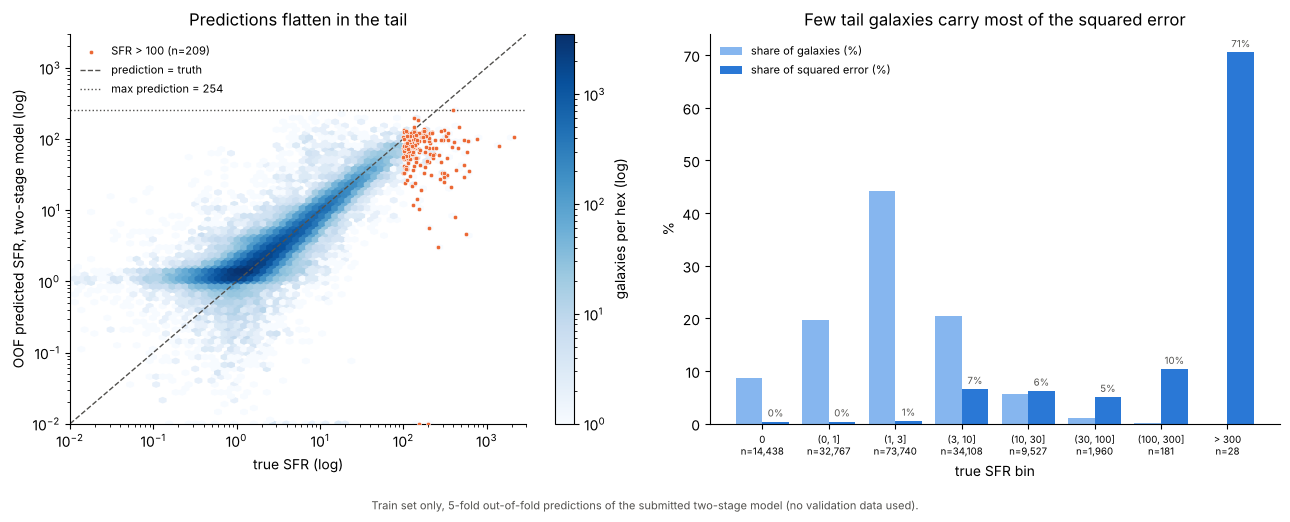

In [7]:
# 그림: 왼쪽 = 양수 은하의 예측 vs 실제 (로그-로그), 오른쪽 = 실제 SFR 구간별 오차제곱합 비중
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
m = yv > 0
hb = ax.hexbin(yv[m], np.clip(pred[m], 1e-2, None), xscale="log", yscale="log", gridsize=70, bins="log", cmap="Blues", mincnt=1)
ax.scatter(yv[in_tail], np.clip(pred[in_tail], 1e-2, None), s=10, color="#eb6834", edgecolor="white", linewidth=0.4,
           label=f"SFR > 100 (n={in_tail.sum()})", zorder=3)
lim = [1e-2, 3e3]
ax.plot(lim, lim, color="#52514e", lw=1, ls="--", label="prediction = truth")
ax.axhline(pred.max(), color="#52514e", lw=1, ls=":", label=f"max prediction = {pred.max():.0f}")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("true SFR (log)"); ax.set_ylabel("OOF predicted SFR, two-stage model (log)")
ax.set_title("Predictions flatten in the tail")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.colorbar(hb, ax=ax, label="galaxies per hex (log)")

ax = axes[1]
xs = np.arange(len(err_tab))
ax.bar(xs - 0.2, err_tab["은하 비율(%)"], width=0.4, color="#86b6ef", label="share of galaxies (%)")
ax.bar(xs + 0.2, err_tab["오차제곱합 비중(%)"], width=0.4, color="#2a78d6", label="share of squared error (%)")
for xi, v in zip(xs, err_tab["오차제곱합 비중(%)"]):
    ax.text(xi + 0.2, v + 1, f"{v:.0f}%", ha="center", fontsize=7, color="#52514e")
ax.set_xticks(xs, [f"{l}\nn={n:,}" for l, n in zip(err_tab.index, err_tab["은하 수"])], fontsize=7)
ax.set_xlabel("true SFR bin"); ax.set_ylabel("%")
ax.set_title("Few tail galaxies carry most of the squared error")
ax.legend(frameon=False, fontsize=8)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.text(0.5, -0.03, "Train set only, 5-fold out-of-fold predictions of the submitted two-stage model (no validation data used).",
         ha="center", fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()


---
## 실험 A: 꼬리 전문 모델 (확률로 섞기)

- 은하를 **0 / 보통(0 < SFR ≤ T) / 꼬리(SFR > T)** 세 부류로 나눠, 3부류 분류기와 부류별 회귀기 2개를 학습한다.
- 예측: **ŷ = P(보통|x)·E[SFR | 보통, x] + P(꼬리|x)·E[SFR | 꼬리, x]** (0 부류는 0을 곱하므로 빠진다). RMSE가 겨냥하는 E[SFR|x]를 정확히 나눈 식이다.
- 비교용으로 "가장 확률이 높은 부류 하나로 보내기"(하드 라우팅)도 만든다.
- 꼬리 경계 T는 10 / 30 / 100 세 후보를 같은 CV에서 비교한다. 모든 단계는 기준선과 같은 HGB 설정이다(변인 통제).
- 평가는 0단계와 같은 학습 데이터 5-fold OOF. 검증 데이터는 쓰지 않는다. 같은 CV에서 T를 고르면 약간 낙관적일 수 있다.


In [8]:
# 실험 A. 꼬리 전문 모델 정의
class TailMixtureSFR:
    """3부류 분류기 P(0/보통/꼬리 | x) × 부류별 회귀기. mode='soft'는 확률로 섞고, 'hard'는 가장 큰 확률의 부류로 보낸다."""
    def __init__(self, hgb_params, tail_threshold, mode="soft"):
        self.hgb_params, self.T, self.mode = hgb_params, tail_threshold, mode
    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        cls = np.where(y == 0, 0, np.where(y <= self.T, 1, 2))
        self.clf_ = HistGradientBoostingClassifier(**self.hgb_params).fit(X, cls)
        self.reg_mid_ = HistGradientBoostingRegressor(**self.hgb_params).fit(X[cls == 1], y[cls == 1])
        self.reg_tail_ = HistGradientBoostingRegressor(**self.hgb_params).fit(X[cls == 2], y[cls == 2])
        self.n_tail_ = int((cls == 2).sum())
        return self
    def parts(self, X):
        P = self.clf_.predict_proba(X)
        e_mid = np.clip(self.reg_mid_.predict(X), 0, None)
        e_tail = np.clip(self.reg_tail_.predict(X), 0, None)
        return P, e_mid, e_tail
    def predict(self, X):
        P, e_mid, e_tail = self.parts(X)
        if self.mode == "soft":
            return P[:, 1] * e_mid + P[:, 2] * e_tail
        k = P.argmax(axis=1)
        return np.select([k == 1, k == 2], [e_mid, e_tail], 0.0)


In [9]:
# 실험 A. 5-fold OOF 예측 (0단계와 같은 fold)
from sklearn.metrics import roc_auc_score
cands = [("soft", 10), ("soft", 30), ("soft", 100), ("hard", 30)]
oofA, ptail, info = {}, {}, []
t0 = time.time()
for mode, T in cands:
    name = f"꼬리 모델 {'확률 섞기' if mode == 'soft' else '하드 라우팅'} T={T}"
    p = np.zeros(len(ytr)); pt = np.zeros(len(ytr))
    for k, (tr, te) in enumerate(FOLDS):
        m = TailMixtureSFR(HGB, T, mode).fit(Xtr.iloc[tr], ytr.iloc[tr])
        p[te] = m.predict(Xtr.iloc[te])
        P, _, _ = m.parts(Xtr.iloc[te]); pt[te] = P[:, 2]
        info.append({"모델": name, "fold": k + 1, "꼬리 학습 은하 수": m.n_tail_,
                     "꼬리 회귀기 트리 수": m.reg_tail_.n_iter_, "보통 회귀기 트리 수": m.reg_mid_.n_iter_})
    oofA[name], ptail[name] = p, pt
print(f"학습·예측 {time.time() - t0:.0f}초")
display(pd.DataFrame(info).groupby("모델", sort=False).agg(
    꼬리_학습_은하_수=("꼬리 학습 은하 수", "mean"), 꼬리_회귀기_트리_수=("꼬리 회귀기 트리 수", "mean"),
    보통_회귀기_트리_수=("보통 회귀기 트리 수", "mean")).round(0))
for name, pt in ptail.items():
    T = int(name.split("T=")[1])
    if "확률" in name:
        print(f"{name}: 꼬리 분류 AUC (SFR > {T} 여부) {roc_auc_score(yv > T, pt):.4f}")


학습·예측 51초


,꼬리_학습_은하_수,꼬리_회귀기_트리_수,보통_회귀기_트리_수
모델,,,
꼬리 모델 확률 섞기 T=10,9357.0,150.0,150.0
꼬리 모델 확률 섞기 T=30,1735.0,150.0,132.0
꼬리 모델 확률 섞기 T=100,167.0,150.0,90.0
꼬리 모델 하드 라우팅 T=30,1735.0,150.0,132.0


꼬리 모델 확률 섞기 T=10: 꼬리 분류 AUC (SFR > 10 여부) 0.9948
꼬리 모델 확률 섞기 T=30: 꼬리 분류 AUC (SFR > 30 여부) 0.9964
꼬리 모델 확률 섞기 T=100: 꼬리 분류 AUC (SFR > 100 여부) 0.5611


In [10]:
# 실험 A. 비교 — 전체·구간별·fold별 (모두 학습 데이터 OOF)
models = {"2단계 (현재 모델)": oof["2단계 (현재 모델)"], **oofA}
regimes = {"SFR = 0": yv == 0, "0 < SFR ≤ 30": (yv > 0) & (yv <= 30), "30 < SFR ≤ 100": (yv > 30) & (yv <= 100),
           "SFR > 100": yv > 100, "SFR > 300": yv > 300}
top5 = np.argsort(yv)[-5:]                     # 가장 큰 은하 5개를 뺀 RMSE (강건성 확인)
keep = np.ones(len(yv), bool); keep[top5] = False
base = models["2단계 (현재 모델)"]
rows = []
for name, p in models.items():
    r = {"모델": name, "OOF RMSE": rmse(yv, p), "fold 평균 RMSE": np.mean([rmse(yv[te], p[te]) for _, te in FOLDS]),
         "최대 5개 제외 RMSE": rmse(yv[keep], p[keep])}
    for rg, m in regimes.items():
        r[f"{rg} RMSE"] = rmse(yv[m], p[m])
    r["SFR>100 평균 잔차"] = (p - yv)[yv > 100].mean()
    r["예측 최댓값"] = p.max()
    r["음수 예측"] = int((p < 0).sum())
    rows.append(r)
cmpA = pd.DataFrame(rows).set_index("모델")
display(cmpA.round(3).T)

# fold별 RMSE 차이 (모델 − 현재 모델, 음수 = 개선)와 쌍 부트스트랩 95% 구간 (OOF 행을 재표집)
rng = np.random.default_rng(RANDOM_SEED)
B = 1000
idx = rng.integers(0, len(yv), size=(B, len(yv)))
fold_rows = []
for name, p in oofA.items():
    d_fold = [rmse(yv[te], p[te]) - rmse(yv[te], base[te]) for _, te in FOLDS]
    se_b, se_m = (base - yv) ** 2, (p - yv) ** 2
    boot = np.sqrt(se_m[idx].mean(axis=1)) - np.sqrt(se_b[idx].mean(axis=1))
    fold_rows.append({"모델": name, "ΔRMSE (OOF)": rmse(yv, p) - rmse(yv, base),
                      "95% 구간": f"[{np.percentile(boot, 2.5):+.3f}, {np.percentile(boot, 97.5):+.3f}]",
                      "fold별 ΔRMSE": [round(x, 3) for x in d_fold],
                      "개선된 fold 수": int(sum(x < 0 for x in d_fold)),
                      "최대 5개 제외 ΔRMSE": rmse(yv[keep], p[keep]) - rmse(yv[keep], base[keep])})
display(pd.DataFrame(fold_rows).set_index("모델").round(3))


모델,2단계 (현재 모델),꼬리 모델 확률 섞기 T=10,꼬리 모델 확률 섞기 T=30,꼬리 모델 확률 섞기 T=100,꼬리 모델 하드 라우팅 T=30
OOF RMSE,9.126,8.856,8.932,11.136,9.768
fold 평균 RMSE,8.455,8.269,8.325,10.791,9.150
최대 5개 제외 RMSE,6.443,6.169,6.238,9.197,6.991
SFR = 0 RMSE,1.908,2.645,2.126,4.362,2.195
0 < SFR ≤ 30 RMSE,3.561,3.812,3.233,6.478,3.403
30 < SFR ≤ 100 RMSE,18.914,20.558,20.467,37.078,22.198
SFR > 100 RMSE,231.805,218.373,227.840,233.650,250.705
SFR > 300 RMSE,591.364,563.774,579.986,585.766,625.742
SFR>100 평균 잔차,-120.671,-101.989,-110.239,-114.034,-117.529
예측 최댓값,254.349,400.251,399.646,610.167,612.998


,ΔRMSE (OOF),95% 구간,fold별 ΔRMSE,개선된 fold 수,최대 5개 제외 ΔRMSE
모델,,,,,
꼬리 모델 확률 섞기 T=10,-0.270,"[-0.629, +0.035]","[-0.619, -0.458, -0.652, 1.107, -0.306]",4,-0.274
꼬리 모델 확률 섞기 T=30,-0.194,"[-0.409, +0.021]","[-0.457, -0.245, -0.202, 0.125, 0.131]",3,-0.205
꼬리 모델 확률 섞기 T=100,2.010,"[+1.225, +2.944]","[1.007, 2.076, 2.325, 3.994, 2.28]",0,2.754
꼬리 모델 하드 라우팅 T=30,0.642,"[+0.303, +0.953]","[0.425, 1.098, 0.524, 0.642, 0.789]",0,0.548


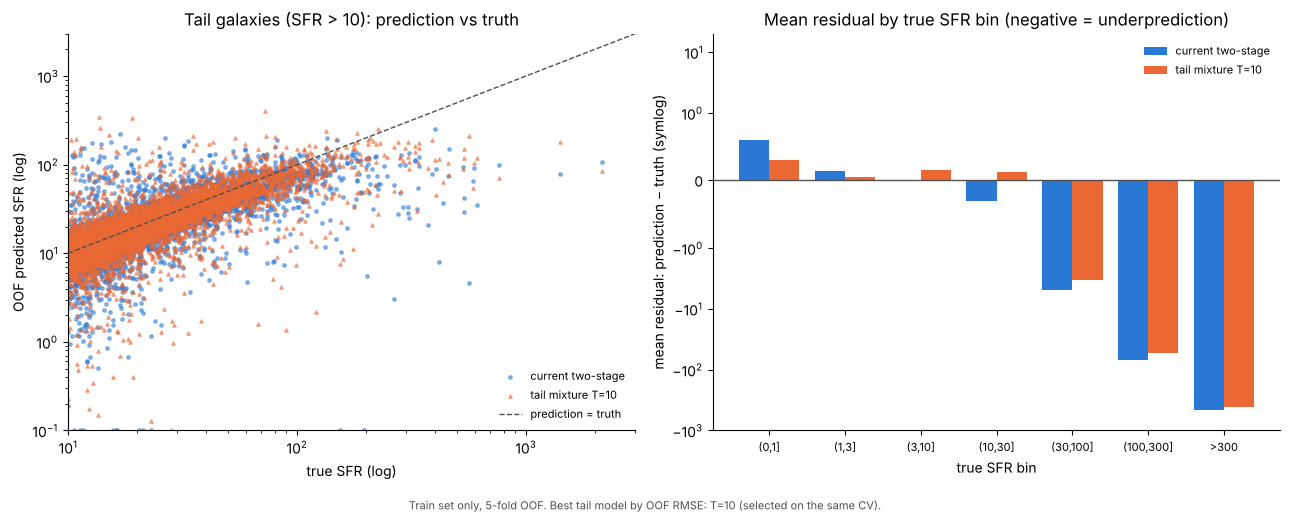

In [11]:
# 그림: 왼쪽 = 꼬리에서 예측 vs 실제 (현재 모델과 가장 좋은 꼬리 모델), 오른쪽 = 실제 SFR 구간별 평균 잔차
best = cmpA.drop(index="2단계 (현재 모델)")["OOF RMSE"].idxmin()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
m = yv > 10
for name, col, mk in [("2단계 (현재 모델)", "#2a78d6", "o"), (best, "#eb6834", "^")]:
    lab = "current two-stage" if name.startswith("2단계") else "tail mixture " + name.split(" ")[-1]
    ax.scatter(yv[m], np.clip(models[name][m], 1e-1, None), s=6, alpha=0.5, color=col, marker=mk, label=lab)
lim = [10, 3e3]
ax.plot(lim, lim, color="#52514e", lw=1, ls="--", label="prediction = truth")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(1e-1, 3e3)
ax.set_xlabel("true SFR (log)"); ax.set_ylabel("OOF predicted SFR (log)")
ax.set_title("Tail galaxies (SFR > 10): prediction vs truth")
ax.legend(frameon=False, fontsize=8, loc="lower right")

ax = axes[1]
bins2 = [0, 1, 3, 10, 30, 100, 300, np.inf]
lab2 = ["(0,1]", "(1,3]", "(3,10]", "(10,30]", "(30,100]", "(100,300]", ">300"]
bb = pd.cut(yv, bins=bins2, labels=lab2)
xs = np.arange(len(lab2))
for j, (name, col) in enumerate([("2단계 (현재 모델)", "#2a78d6"), (best, "#eb6834")]):
    mr = pd.Series(models[name] - yv).groupby(bb, observed=True).mean()
    ax.bar(xs + (j - 0.5) * 0.4, mr.values, width=0.4, color=col,
           label="current two-stage" if j == 0 else "tail mixture " + best.split(" ")[-1])
ax.axhline(0, color="#52514e", lw=1)
ax.set_yscale("symlog", linthresh=1)
ax.set_ylim(-1000, 20)
ax.set_xticks(xs, lab2, fontsize=8)
ax.set_xlabel("true SFR bin"); ax.set_ylabel("mean residual: prediction − truth (symlog)")
ax.set_title("Mean residual by true SFR bin (negative = underprediction)")
ax.legend(frameon=False, fontsize=8)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.text(0.5, -0.03, f"Train set only, 5-fold OOF. Best tail model by OOF RMSE: {best.split(' ')[-1]} (selected on the same CV).",
         ha="center", fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()


---
## 실험 B: 0 판단은 그대로, 양수 안에서만 보통/꼬리 나누기

실험 A는 꼬리를 조금 개선했지만, 0 확률을 3부류 분류기가 맡으면서 SFR = 0 RMSE가 나빠졌다. 그래서 **0 판단은 현재 모델의 2부류 분류기를 그대로** 쓰고, 양수 은하 안에서만 보통/꼬리를 나눈다.

**ŷ = P(SFR>0 | x) × [ P(꼬리 | SFR>0, x)·E[SFR | 꼬리, x] + (1 − P(꼬리 | SFR>0, x))·E[SFR | 보통, x] ]**

- P(SFR>0|x): 현재 2단계 모델과 같은 분류기 (전체 학습 은하)
- P(꼬리|SFR>0, x): 양수 은하만으로 학습한 2부류 분류기 (SFR > T vs 0 < SFR ≤ T)
- 보통·꼬리 회귀기: 실험 A와 같음
- T = 10, 30. 같은 HGB 설정, 같은 fold, 검증 데이터 미사용.


In [12]:
# 실험 B. 모델 정의
class NestedTailSFR:
    """P(>0) × [P(꼬리|>0)·E꼬리 + (1−P(꼬리|>0))·E보통]. 0 판단은 현재 2단계 모델과 같은 2부류 분류기."""
    def __init__(self, hgb_params, tail_threshold):
        self.hgb_params, self.T = hgb_params, tail_threshold
    def fit(self, X, y):
        y = np.asarray(y, dtype=float); pos = y > 0
        Xp, yp = X[pos], y[pos]; tail = yp > self.T
        self.clf_zero_ = HistGradientBoostingClassifier(**self.hgb_params).fit(X, pos.astype(int))
        self.clf_tail_ = HistGradientBoostingClassifier(**self.hgb_params).fit(Xp, tail.astype(int))
        self.reg_mid_ = HistGradientBoostingRegressor(**self.hgb_params).fit(Xp[~tail], yp[~tail])
        self.reg_tail_ = HistGradientBoostingRegressor(**self.hgb_params).fit(Xp[tail], yp[tail])
        return self
    def parts(self, X):
        p_pos = self.clf_zero_.predict_proba(X)[:, 1]
        p_tail = self.clf_tail_.predict_proba(X)[:, 1]
        e_mid = np.clip(self.reg_mid_.predict(X), 0, None)
        e_tail = np.clip(self.reg_tail_.predict(X), 0, None)
        return p_pos, p_tail, e_mid, e_tail
    def predict(self, X):
        p_pos, p_tail, e_mid, e_tail = self.parts(X)
        return p_pos * (p_tail * e_tail + (1 - p_tail) * e_mid)


In [13]:
# 실험 B. 5-fold OOF 예측 (0단계·실험 A와 같은 fold)
oofB, infoB = {}, []
t0 = time.time()
for T in (10, 30):
    name = f"실험 B (0 판단 유지) T={T}"
    p = np.zeros(len(ytr)); pt = np.zeros(len(ytr))
    for k, (tr, te) in enumerate(FOLDS):
        m = NestedTailSFR(HGB, T).fit(Xtr.iloc[tr], ytr.iloc[tr])
        p[te] = m.predict(Xtr.iloc[te]); pt[te] = m.parts(Xtr.iloc[te])[1]
        infoB.append({"모델": name, "fold": k + 1, "꼬리 분류기 트리 수": m.clf_tail_.n_iter_,
                      "꼬리 회귀기 트리 수": m.reg_tail_.n_iter_, "보통 회귀기 트리 수": m.reg_mid_.n_iter_})
    oofB[name] = p
    pos_m = yv > 0
    print(f"{name}: 양수 은하 안 꼬리 분류 AUC (SFR > {T}) {roc_auc_score(yv[pos_m] > T, pt[pos_m]):.4f}")
print(f"학습·예측 {time.time() - t0:.0f}초")
display(pd.DataFrame(infoB).groupby("모델", sort=False).mean(numeric_only=True).drop(columns="fold").round(0))


실험 B (0 판단 유지) T=10: 양수 은하 안 꼬리 분류 AUC (SFR > 10) 0.9945


실험 B (0 판단 유지) T=30: 양수 은하 안 꼬리 분류 AUC (SFR > 30) 0.9963
학습·예측 28초


,꼬리 분류기 트리 수,꼬리 회귀기 트리 수,보통 회귀기 트리 수
모델,,,
실험 B (0 판단 유지) T=10,114.0,150.0,150.0
실험 B (0 판단 유지) T=30,76.0,150.0,132.0


In [14]:
# 실험 B. 비교 — 현재 모델, 실험 A의 가장 좋은 두 모델, 실험 B (모두 학습 데이터 OOF)
modelsB = {"2단계 (현재 모델)": oof["2단계 (현재 모델)"],
           "실험 A 섞기 T=10": oofA["꼬리 모델 확률 섞기 T=10"], "실험 A 섞기 T=30": oofA["꼬리 모델 확률 섞기 T=30"],
           **oofB}
rows = []
for name, p in modelsB.items():
    r = {"모델": name, "OOF RMSE": rmse(yv, p), "fold 평균 RMSE": np.mean([rmse(yv[te], p[te]) for _, te in FOLDS]),
         "최대 5개 제외 RMSE": rmse(yv[keep], p[keep])}
    for rg, m in regimes.items():
        r[f"{rg} RMSE"] = rmse(yv[m], p[m])
    r["SFR>100 평균 잔차"] = (p - yv)[yv > 100].mean()
    r["전체 MAE"] = np.abs(p - yv).mean()
    r["예측 평균 (실제 평균 %.3f)" % yv.mean()] = p.mean()
    r["예측 최댓값"] = p.max()
    rows.append(r)
cmpB = pd.DataFrame(rows).set_index("모델")
display(cmpB.round(3).T)

fold_rowsB = []
for name, p in list(modelsB.items())[1:]:
    d_fold = [rmse(yv[te], p[te]) - rmse(yv[te], base[te]) for _, te in FOLDS]
    se_b, se_m = (base - yv) ** 2, (p - yv) ** 2
    boot = np.sqrt(se_m[idx].mean(axis=1)) - np.sqrt(se_b[idx].mean(axis=1))
    fold_rowsB.append({"모델": name, "ΔRMSE (OOF)": rmse(yv, p) - rmse(yv, base),
                       "95% 구간": f"[{np.percentile(boot, 2.5):+.3f}, {np.percentile(boot, 97.5):+.3f}]",
                       "fold별 ΔRMSE": [round(x, 3) for x in d_fold],
                       "개선된 fold 수": int(sum(x < 0 for x in d_fold)),
                       "최대 5개 제외 ΔRMSE": rmse(yv[keep], p[keep]) - rmse(yv[keep], base[keep]),
                       "SFR = 0 ΔRMSE": rmse(yv[yv == 0], p[yv == 0]) - rmse(yv[yv == 0], base[yv == 0])})
display(pd.DataFrame(fold_rowsB).set_index("모델").round(3))


모델,2단계 (현재 모델),실험 A 섞기 T=10,실험 A 섞기 T=30,실험 B (0 판단 유지) T=10,실험 B (0 판단 유지) T=30
OOF RMSE,9.126,8.856,8.932,8.818,8.798
fold 평균 RMSE,8.455,8.269,8.325,8.216,8.129
최대 5개 제외 RMSE,6.443,6.169,6.238,6.050,5.985
SFR = 0 RMSE,1.908,2.645,2.126,2.293,1.882
0 < SFR ≤ 30 RMSE,3.561,3.812,3.233,3.691,3.169
30 < SFR ≤ 100 RMSE,18.914,20.558,20.467,20.005,18.626
SFR > 100 RMSE,231.805,218.373,227.840,219.375,225.934
SFR > 300 RMSE,591.364,563.774,579.986,568.097,579.504
SFR>100 평균 잔차,-120.671,-101.989,-110.239,-102.204,-110.834
전체 MAE,1.195,1.077,1.086,1.076,1.080


,ΔRMSE (OOF),95% 구간,fold별 ΔRMSE,개선된 fold 수,최대 5개 제외 ΔRMSE,SFR = 0 ΔRMSE
모델,,,,,,
실험 A 섞기 T=10,-0.270,"[-0.629, +0.035]","[-0.619, -0.458, -0.652, 1.107, -0.306]",4,-0.274,0.737
실험 A 섞기 T=30,-0.194,"[-0.409, +0.021]","[-0.457, -0.245, -0.202, 0.125, 0.131]",3,-0.205,0.219
실험 B (0 판단 유지) T=10,-0.309,"[-0.677, +0.002]","[-0.573, -0.558, -0.553, 0.923, -0.431]",4,-0.393,0.385
실험 B (0 판단 유지) T=30,-0.328,"[-0.597, -0.115]","[-0.299, -0.615, -0.472, 0.086, -0.329]",4,-0.458,-0.026


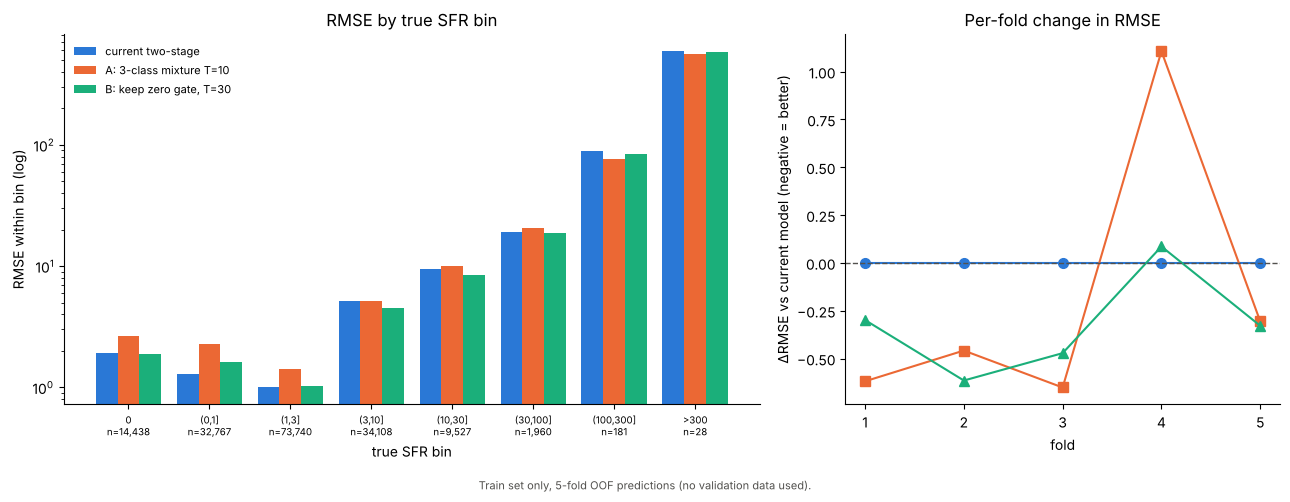

In [15]:
# 그림: 실제 SFR 구간별 RMSE — 현재 모델, 실험 A T=10, 실험 B의 더 나은 쪽
bestB = cmpB.loc[[k for k in cmpB.index if k.startswith("실험 B")], "OOF RMSE"].idxmin()
show = [("2단계 (현재 모델)", "current two-stage", "#2a78d6"),
        ("실험 A 섞기 T=10", "A: 3-class mixture T=10", "#eb6834"),
        (bestB, "B: keep zero gate, " + bestB.split(" ")[-1], "#1baf7a")]
bins3 = [-0.1, 0, 1, 3, 10, 30, 100, 300, np.inf]
lab3 = ["0", "(0,1]", "(1,3]", "(3,10]", "(10,30]", "(30,100]", "(100,300]", ">300"]
bb3 = pd.cut(yv, bins=bins3, labels=lab3)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
xs = np.arange(len(lab3)); w = 0.27
for j, (name, lab, col) in enumerate(show):
    r_bin = pd.Series((modelsB[name] - yv) ** 2).groupby(bb3, observed=True).mean() ** 0.5
    ax.bar(xs + (j - 1) * w, r_bin.values, width=w, color=col, label=lab)
ax.set_yscale("log")
ax.set_xticks(xs, [f"{l}\nn={n:,}" for l, n in zip(lab3, pd.Series(yv).groupby(bb3, observed=True).size())], fontsize=7)
ax.set_xlabel("true SFR bin"); ax.set_ylabel("RMSE within bin (log)")
ax.set_title("RMSE by true SFR bin")
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax = axes[1]
for j, (name, lab, col) in enumerate(show):
    d = [rmse(yv[te], modelsB[name][te]) - rmse(yv[te], base[te]) for _, te in FOLDS]
    ax.plot(range(1, 6), d, marker="os^"[j], color=col, lw=1.5, ms=7, label=lab)
ax.axhline(0, color="#52514e", lw=1, ls="--")
ax.set_xticks(range(1, 6)); ax.set_xlabel("fold")
ax.set_ylabel("ΔRMSE vs current model (negative = better)")
ax.set_title("Per-fold change in RMSE")
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.text(0.5, -0.03, "Train set only, 5-fold OOF predictions (no validation data used).", ha="center", fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()


---
## 실험 C: 가장 극단적인 꼬리(SFR > 300) — 구별 가능성, 회귀기 설정, 가중치

실험 B T=30 구조는 그대로 두고 **꼬리 회귀기만** 바꾼다. 0 판단 분류기, 꼬리 분류기, 보통 회귀기는 실험 B와 같다.

- **C0 구별 가능성:** 꼬리(SFR > 30) 안에서 SFR > 300을 피처로 얼마나 가를 수 있나 (OOF AUC). 정보가 없으면 어떤 가중치도 소용없다.
- **C1 설정:** `min_samples_leaf` 10·5, 트리 300개 (가중치 없음) — 덜 배운 문제
- **C2 가중치:** 꼬리 회귀기에 SFR^0.5, SFR^1 비례 가중치 — 예측을 위로 끌어올림 (대신 평균 예측에서 벗어남)
- **C3 설정 + 가중치:** `min_samples_leaf` 5 + SFR^0.5

같은 fold, 학습 데이터만. 후보가 많을수록 우연히 좋아 보이는 것을 고를 위험이 커지므로 후보는 5개로 제한한다.


In [16]:
# C0. 꼬리(SFR > 30) 안에서 SFR > 300을 가를 수 있나 — 같은 fold의 OOF
T_B = 30
c0_rows = []
for msl in (20, 5):
    s = np.full(len(ytr), np.nan)
    for tr, te in FOLDS:
        trm = tr[yv[tr] > T_B]; tem = te[yv[te] > T_B]
        clf = HistGradientBoostingClassifier(**{**HGB, "min_samples_leaf": msl}).fit(Xtr.iloc[trm], (yv[trm] > 300).astype(int))
        s[tem] = clf.predict_proba(Xtr.iloc[tem])[:, 1]
    mt = yv > T_B
    c0_rows.append({"방법": f"분류기 (min_samples_leaf={msl})", "AUC: >300 vs 30~300": roc_auc_score(yv[mt] > 300, s[mt]),
                    "AUC: >300 vs 100~300": roc_auc_score(yv[yv > 100] > 300, s[yv > 100])})
# 실험 B T=30의 꼬리 회귀기 예측 순위도 같은 질문에 대한 답이 된다
e_tail_B = np.zeros(len(ytr))
for tr, te in FOLDS:
    pos_tr = tr[yv[tr] > T_B]
    reg = HistGradientBoostingRegressor(**HGB).fit(Xtr.iloc[pos_tr], yv[pos_tr])
    e_tail_B[te] = reg.predict(Xtr.iloc[te])
mt = yv > T_B
c0_rows.append({"방법": "실험 B 꼬리 회귀기 예측값 순위", "AUC: >300 vs 30~300": roc_auc_score(yv[mt] > 300, e_tail_B[mt]),
                "AUC: >300 vs 100~300": roc_auc_score(yv[yv > 100] > 300, e_tail_B[yv > 100])})
display(pd.DataFrame(c0_rows).set_index("방법").round(3))
print(f"꼬리(SFR > 30) {mt.sum():,}개 중 SFR > 300: {(yv > 300).sum()}개 | SFR > 100: {(yv > 100).sum()}개")
print("꼬리 회귀기 예측과 실제 SFR의 Spearman (SFR > 30 안):",
      round(pd.Series(e_tail_B[mt]).corr(pd.Series(yv[mt]), method="spearman"), 3),
      "| SFR > 100 안:", round(pd.Series(e_tail_B[yv > 100]).corr(pd.Series(yv[yv > 100]), method="spearman"), 3))


,AUC: >300 vs 30~300,AUC: >300 vs 100~300
방법,,
분류기 (min_samples_leaf=20),0.946,0.819
분류기 (min_samples_leaf=5),0.965,0.822
실험 B 꼬리 회귀기 예측값 순위,0.974,0.826


꼬리(SFR > 30) 2,169개 중 SFR > 300: 28개 | SFR > 100: 209개
꼬리 회귀기 예측과 실제 SFR의 Spearman (SFR > 30 안): 0.707 | SFR > 100 안: 0.572


In [17]:
# C1~C3. 실험 B T=30에서 꼬리 회귀기만 바꾼다 (다른 부분은 fold마다 한 번 학습해 재사용)
variants = {
    "C1 잎 최소 10, 트리 300": (dict(min_samples_leaf=10, max_iter=300), None),
    "C1 잎 최소 5, 트리 300": (dict(min_samples_leaf=5, max_iter=300), None),
    "C2 가중치 SFR^0.5": (dict(), 0.5),
    "C2 가중치 SFR^1": (dict(), 1.0),
    "C3 잎 최소 5 + SFR^0.5": (dict(min_samples_leaf=5, max_iter=300), 0.5),
}
oofC = {k: np.zeros(len(ytr)) for k in variants}
oofB30 = np.zeros(len(ytr))
t0 = time.time()
for tr, te in FOLDS:
    Xa, ya = Xtr.iloc[tr], yv[tr]
    pos = ya > 0; tail = ya > T_B
    clf0 = HistGradientBoostingClassifier(**HGB).fit(Xa, pos.astype(int))
    clft = HistGradientBoostingClassifier(**HGB).fit(Xa[pos], tail[pos].astype(int))
    regm = HistGradientBoostingRegressor(**HGB).fit(Xa[pos & ~tail], ya[pos & ~tail])
    Xb = Xtr.iloc[te]
    p_pos = clf0.predict_proba(Xb)[:, 1]; p_t = clft.predict_proba(Xb)[:, 1]; e_m = np.clip(regm.predict(Xb), 0, None)
    regt = HistGradientBoostingRegressor(**HGB).fit(Xa[tail], ya[tail])
    oofB30[te] = p_pos * (p_t * np.clip(regt.predict(Xb), 0, None) + (1 - p_t) * e_m)
    for name, (extra, alpha) in variants.items():
        w = None if alpha is None else ya[tail] ** alpha
        r = HistGradientBoostingRegressor(**{**HGB, **extra}).fit(Xa[tail], ya[tail], sample_weight=w)
        oofC[name][te] = p_pos * (p_t * np.clip(r.predict(Xb), 0, None) + (1 - p_t) * e_m)
print(f"학습·예측 {time.time() - t0:.0f}초 | 실험 B T=30 재현 확인 (최대 차이):",
      float(np.abs(oofB30 - oofB["실험 B (0 판단 유지) T=30"]).max()))


학습·예측 55초 | 실험 B T=30 재현 확인 (최대 차이): 0.0


In [18]:
# C 비교 — 기준은 현재 모델과 실험 B T=30
modelsC = {"2단계 (현재 모델)": oof["2단계 (현재 모델)"], "실험 B T=30": oofB30, **oofC}
bins4 = {"SFR = 0": yv == 0, "0 < SFR ≤ 30": (yv > 0) & (yv <= 30), "30 < SFR ≤ 100": (yv > 30) & (yv <= 100),
         "100 < SFR ≤ 300": (yv > 100) & (yv <= 300), "SFR > 300": yv > 300}
rows = []
for name, p in modelsC.items():
    r = {"모델": name, "OOF RMSE": rmse(yv, p), "fold 평균 RMSE": np.mean([rmse(yv[te], p[te]) for _, te in FOLDS]),
         "최대 5개 제외 RMSE": rmse(yv[keep], p[keep])}
    for rg, m in bins4.items():
        r[f"{rg} RMSE"] = rmse(yv[m], p[m])
    for rg in ("30 < SFR ≤ 100", "100 < SFR ≤ 300", "SFR > 300"):
        r[f"{rg} 평균 잔차"] = (p - yv)[bins4[rg]].mean()
    r["예측 평균 (실제 %.3f)" % yv.mean()] = p.mean()
    r["예측 최댓값"] = p.max()
    rows.append(r)
cmpC = pd.DataFrame(rows).set_index("모델")
display(cmpC.round(3).T)

refs = {"현재 모델 대비": oof["2단계 (현재 모델)"], "실험 B T=30 대비": oofB30}
fold_rowsC = []
for name, p in oofC.items():
    row = {"모델": name}
    for rname, ref in refs.items():
        d_fold = [rmse(yv[te], p[te]) - rmse(yv[te], ref[te]) for _, te in FOLDS]
        boot = np.sqrt(((p - yv) ** 2)[idx].mean(axis=1)) - np.sqrt(((ref - yv) ** 2)[idx].mean(axis=1))
        row[f"{rname} ΔRMSE"] = rmse(yv, p) - rmse(yv, ref)
        row[f"{rname} 95% 구간"] = f"[{np.percentile(boot, 2.5):+.3f}, {np.percentile(boot, 97.5):+.3f}]"
        row[f"{rname} 개선 fold"] = int(sum(x < 0 for x in d_fold))
    row["B 대비 fold별 Δ"] = [round(rmse(yv[te], p[te]) - rmse(yv[te], oofB30[te]), 3) for _, te in FOLDS]
    row["B 대비 최대 5개 제외 Δ"] = rmse(yv[keep], p[keep]) - rmse(yv[keep], oofB30[keep])
    fold_rowsC.append(row)
display(pd.DataFrame(fold_rowsC).set_index("모델").round(3).T)


모델,2단계 (현재 모델),실험 B T=30,"C1 잎 최소 10, 트리 300","C1 잎 최소 5, 트리 300",C2 가중치 SFR^0.5,C2 가중치 SFR^1,C3 잎 최소 5 + SFR^0.5
OOF RMSE,9.126,8.798,8.953,8.943,9.030,9.176,8.821
fold 평균 RMSE,8.455,8.129,8.315,8.293,8.428,8.602,8.172
최대 5개 제외 RMSE,6.443,5.985,6.140,6.127,6.315,6.634,6.043
SFR = 0 RMSE,1.908,1.882,2.037,2.119,1.988,2.091,2.296
0 < SFR ≤ 30 RMSE,3.561,3.169,3.529,3.268,3.734,3.966,3.157
30 < SFR ≤ 100 RMSE,18.914,18.626,19.525,19.582,21.564,26.216,18.679
100 < SFR ≤ 300 RMSE,89.145,83.618,81.407,83.696,79.374,79.615,85.521
SFR > 300 RMSE,591.364,579.504,582.169,587.022,579.268,570.767,579.217
30 < SFR ≤ 100 평균 잔차,-4.878,-3.593,-3.537,-3.627,-2.468,-1.992,-3.389
100 < SFR ≤ 300 평균 잔차,-68.847,-60.167,-56.037,-57.884,-55.817,-54.697,-56.574


모델,"C1 잎 최소 10, 트리 300","C1 잎 최소 5, 트리 300",C2 가중치 SFR^0.5,C2 가중치 SFR^1,C3 잎 최소 5 + SFR^0.5
현재 모델 대비 ΔRMSE,-0.173,-0.183,-0.096,0.05,-0.305
현재 모델 대비 95% 구간,"[-0.478, +0.069]","[-0.472, +0.046]","[-0.379, +0.172]","[-0.281, +0.419]","[-0.581, -0.082]"
현재 모델 대비 개선 fold,4,4,4,2,4
실험 B T=30 대비 ΔRMSE,0.155,0.145,0.232,0.378,0.023
실험 B T=30 대비 95% 구간,"[+0.033, +0.301]","[+0.018, +0.303]","[+0.072, +0.450]","[+0.101, +0.759]","[-0.134, +0.226]"
실험 B T=30 대비 개선 fold,1,1,1,0,2
B 대비 fold별 Δ,"[0.137, 0.095, -0.122, 0.496, 0.323]","[0.116, 0.15, 0.033, 0.569, -0.047]","[-0.057, 0.481, 0.106, 0.646, 0.319]","[0.01, 0.666, 0.234, 0.901, 0.555]","[-0.177, 0.279, -0.276, 0.165, 0.227]"
B 대비 최대 5개 제외 Δ,0.155,0.142,0.33,0.649,0.058


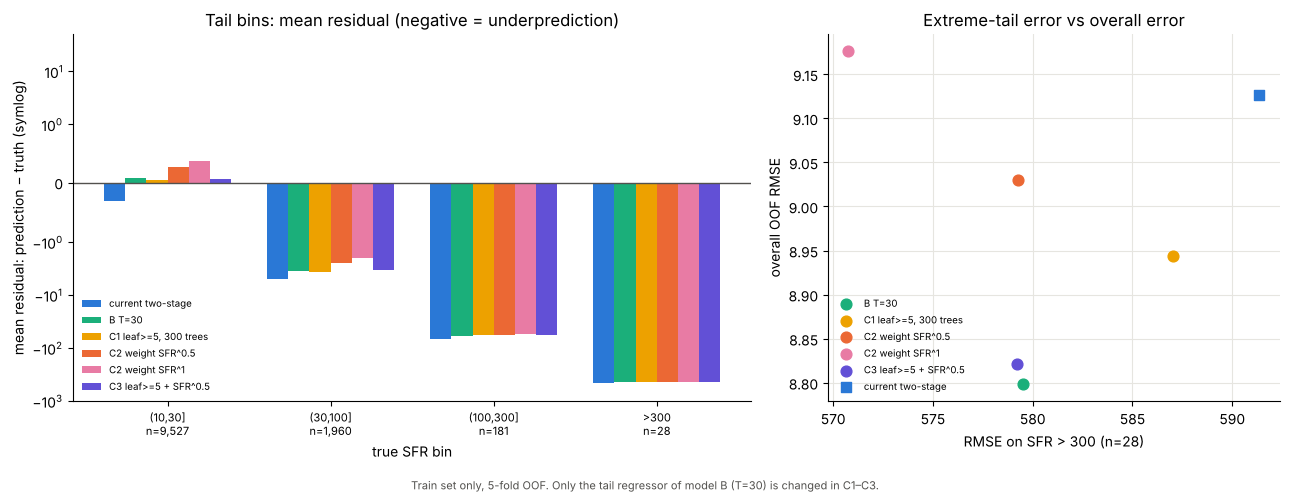

In [19]:
# 그림: 꼬리 구간별 평균 잔차 (위로 끌어올리면 어느 구간이 과대예측으로 바뀌는지)
show = ["2단계 (현재 모델)", "실험 B T=30", "C1 잎 최소 5, 트리 300", "C2 가중치 SFR^0.5", "C2 가중치 SFR^1", "C3 잎 최소 5 + SFR^0.5"]
labels_en = ["current two-stage", "B T=30", "C1 leaf>=5, 300 trees", "C2 weight SFR^0.5", "C2 weight SFR^1", "C3 leaf>=5 + SFR^0.5"]
cols = ["#2a78d6", "#1baf7a", "#eda100", "#eb6834", "#e87ba4", "#6250d6"]
bins5 = [10, 30, 100, 300, np.inf]; lab5 = ["(10,30]", "(30,100]", "(100,300]", ">300"]
bb5 = pd.cut(yv, bins=bins5, labels=lab5)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
xs = np.arange(len(lab5)); w = 0.13
for j, (name, le, col) in enumerate(zip(show, labels_en, cols)):
    mr = pd.Series(modelsC[name] - yv).groupby(bb5, observed=True).mean()
    ax.bar(xs + (j - 2.5) * w, mr.values, width=w, color=col, label=le)
ax.axhline(0, color="#52514e", lw=1)
ax.set_yscale("symlog", linthresh=1); ax.set_ylim(-1000, 50)
ax.set_xticks(xs, [f"{l}\nn={n:,}" for l, n in zip(lab5, pd.Series(yv[yv > 10]).groupby(bb5[yv > 10], observed=True).size())], fontsize=8)
ax.set_xlabel("true SFR bin"); ax.set_ylabel("mean residual: prediction − truth (symlog)")
ax.set_title("Tail bins: mean residual (negative = underprediction)")
ax.legend(frameon=False, fontsize=7, loc="lower left")
ax = axes[1]
for j, (name, le, col) in enumerate(zip(show[1:], labels_en[1:], cols[1:])):
    ax.scatter(cmpC.loc[name, "SFR > 300 RMSE"], cmpC.loc[name, "OOF RMSE"], s=60, color=col, label=le, zorder=3)
ax.scatter(cmpC.loc[show[0], "SFR > 300 RMSE"], cmpC.loc[show[0], "OOF RMSE"], s=60, color=cols[0], marker="s", label=labels_en[0], zorder=3)
ax.set_xlabel("RMSE on SFR > 300 (n=28)"); ax.set_ylabel("overall OOF RMSE")
ax.set_title("Extreme-tail error vs overall error")
ax.legend(frameon=False, fontsize=7)
for a in axes: a.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
fig.text(0.5, -0.03, "Train set only, 5-fold OOF. Only the tail regressor of model B (T=30) is changed in C1–C3.", ha="center", fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()


---
## 최종 확인: 검증 데이터로 한 번만 (실험 B T=30)

- 학습 데이터 CV에서 후보 11개를 비교한 뒤 **실험 B T=30을 최종 후보로 고정**했다(아래 코드에서 바꾸지 않는다).
- 여기서 처음으로 검증 데이터(41,688개)를 쓴다. 학습은 전체 학습 데이터로 한 번, 평가는 검증 데이터로 한 번.
- 비교: 템플릿 HGB 기준선, 제출본 2단계 모델(조장 7절, val RMSE 9.434). 지표는 템플릿 `evaluate_sfr`와 같은 정의, 구간은 조장 7절과 같은 쌍 부트스트랩(B = 1000, 재표집 단위 = 검증 은하 한 개).
- 이 결과를 보고 모델을 다시 고르지 않는다. 고르면 검증 결과도 낙관적이 된다.


In [20]:
# 검증 데이터 준비 (템플릿 5절과 같은 분할)
from sklearn.metrics import mean_absolute_error, r2_score
X_train_f, X_val, y_train_f, y_val = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_SEED, stratify=(y > 0).astype(int))
assert X_train_f.index.equals(X_train.index)

def regression_metrics(y_true, y_pred):      # 템플릿 DO NOT MODIFY 칸과 같은 정의
    y_true = np.asarray(y_true, dtype=float); y_pred = np.asarray(y_pred, dtype=float)
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "R2": r2_score(y_true, y_pred)}

def evaluate_sfr(y_true, y_pred, label="Model"):
    y_true = np.asarray(y_true, dtype=float); y_pred = np.asarray(y_pred, dtype=float)
    masks = {"All": np.ones(len(y_true), dtype=bool), "SFR = 0": y_true == 0, "SFR > 0": y_true > 0,
             "Top 10% SFR": y_true >= np.quantile(y_true, 0.90)}
    return pd.DataFrame([{"Model": label, "Regime": k, "N": int(m.sum()), **regression_metrics(y_true[m], y_pred[m])}
                         for k, m in masks.items() if m.sum()])

def paired_rmse_ci(pred_a, pred_b, y, B=1000, seed=RANDOM_SEED, chunk=100):   # 조장 7절과 같은 방식
    y = np.asarray(y, float)
    ea, eb = (np.asarray(pred_a) - y) ** 2, (np.asarray(pred_b) - y) ** 2
    rng = np.random.default_rng(seed); diffs = []
    for _ in range(B // chunk):
        ii = rng.integers(0, len(y), size=(chunk, len(y)), dtype=np.int32)
        diffs.append(np.sqrt(eb[ii].mean(axis=1)) - np.sqrt(ea[ii].mean(axis=1)))
    diffs = np.concatenate(diffs)
    return float(np.sqrt(eb.mean()) - np.sqrt(ea.mean())), float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))


In [21]:
# 세 모델을 전체 학습 데이터로 학습하고 검증 데이터로 한 번 평가
val_pred = {
    "HGB 기준선": HistGradientBoostingRegressor(**HGB).fit(X_train, y_train).predict(X_val),
    "2단계 (제출본)": TwoStageSFR(HGB).fit(X_train, y_train).predict(X_val),
    "실험 B T=30 (꼬리 분리)": NestedTailSFR(HGB, 30).fit(X_train, y_train).predict(X_val),
}
yvl = y_val.to_numpy()
tab = pd.concat([evaluate_sfr(yvl, p, k) for k, p in val_pred.items()], ignore_index=True)
display(tab.pivot(index="Regime", columns="Model", values="RMSE").loc[["All", "SFR = 0", "SFR > 0", "Top 10% SFR"]]
        [list(val_pred)].round(3).rename_axis("RMSE"))
display(tab.pivot(index="Regime", columns="Model", values="MAE").loc[["All", "SFR = 0", "SFR > 0", "Top 10% SFR"]]
        [list(val_pred)].round(3).rename_axis("MAE"))
print("제출본 값과 재현 확인 — 기준선 9.513, 2단계 9.434 (조장 7.1):",
      {k: round(rmse(yvl, p), 3) for k, p in val_pred.items()})

ci = []
for ref in ("HGB 기준선", "2단계 (제출본)"):
    d, lo, hi = paired_rmse_ci(val_pred[ref], val_pred["실험 B T=30 (꼬리 분리)"], yvl)
    ci.append({"비교": f"실험 B T=30 − {ref}", "ΔRMSE": d, "95% 구간 하한": lo, "95% 구간 상한": hi,
               "판정": "개선" if hi < 0 else ("악화" if lo > 0 else "동등(구간이 0 포함)")})
display(pd.DataFrame(ci).set_index("비교").round(3))

# 꼬리 구간별 (검증) — 어디서 달라졌나
bins_v = [-0.1, 0, 1, 3, 10, 30, 100, 300, np.inf]
lab_v = ["0", "(0,1]", "(1,3]", "(3,10]", "(10,30]", "(30,100]", "(100,300]", ">300"]
bv = pd.cut(yvl, bins=bins_v, labels=lab_v)
by_bin = pd.DataFrame({"은하 수": pd.Series(yvl).groupby(bv, observed=True).size()})
for k, p in val_pred.items():
    by_bin[f"{k} RMSE"] = (pd.Series((p - yvl) ** 2).groupby(bv, observed=True).mean()) ** 0.5
    by_bin[f"{k} 평균 잔차"] = pd.Series(p - yvl).groupby(bv, observed=True).mean()
display(by_bin.round(2))
print("예측 최댓값:", {k: round(float(p.max()), 1) for k, p in val_pred.items()}, "| 검증 실제 최댓값:", round(float(yvl.max()), 1))


Model,HGB 기준선,2단계 (제출본),실험 B T=30 (꼬리 분리)
RMSE,,,
All,9.513,9.434,8.784
SFR = 0,3.551,2.913,2.429
SFR > 0,9.894,9.830,9.160
Top 10% SFR,29.404,29.149,27.054


Model,HGB 기준선,2단계 (제출본),실험 B T=30 (꼬리 분리)
MAE,,,
All,1.296,1.240,1.098
SFR = 0,1.214,0.554,0.452
SFR > 0,1.303,1.305,1.159
Top 10% SFR,6.583,6.561,5.874


제출본 값과 재현 확인 — 기준선 9.513, 2단계 9.434 (조장 7.1): {'HGB 기준선': 9.513, '2단계 (제출본)': 9.434, '실험 B T=30 (꼬리 분리)': 8.784}


,ΔRMSE,95% 구간 하한,95% 구간 상한,판정
비교,,,,
실험 B T=30 − HGB 기준선,-0.729,-1.368,-0.202,개선
실험 B T=30 − 2단계 (제출본),-0.650,-1.441,0.046,동등(구간이 0 포함)


,은하 수,HGB 기준선 RMSE,HGB 기준선 평균 잔차,2단계 (제출본) RMSE,2단계 (제출본) 평균 잔차,실험 B T=30 (꼬리 분리) RMSE,실험 B T=30 (꼬리 분리) 평균 잔차
0,3610,3.55,1.21,2.91,0.55,2.43,0.45
"(0,1]",8198,1.24,0.62,1.48,0.65,0.94,0.30
"(1,3]",18323,1.47,0.13,1.38,0.18,1.84,0.08
"(3,10]",8619,3.17,-0.24,3.49,-0.18,3.17,-0.01
"(10,30]",2403,8.23,-0.96,7.41,-0.88,6.65,-0.18
"(30,100]",474,20.64,-5.38,22.47,-4.94,16.83,-4.29
"(100,300]",50,97.95,-76.72,103.01,-78.02,89.14,-63.32
>300,11,499.50,-468.93,488.06,-454.85,467.26,-434.46


예측 최댓값: {'HGB 기준선': 175.6, '2단계 (제출본)': 202.2, '실험 B T=30 (꼬리 분리)': 211.7} | 검증 실제 최댓값: 884.1
